In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import roc_curve
from matplotlib.cm import get_cmap

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import get_nnmd, annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
TEMPDIR = Path(config['TEMPDIR'])
cell_line_dict=config['cell_lines']
cell_lines = list(cell_line_dict.values())

In [2]:
# Load DepMap data
df = pd.read_csv("/scratch/peidli/DepMap/depmap_export_2024-06-13 08_40_33.976743_subsetted_NAsdropped.csv", index_col=1)
df = df.loc[:, (~df.isna()).sum(0) != 0]  # remove all-nan columns
# df = df.drop('depmap_id', axis=1)
df.index = df.index.str.replace("NCI", "")

In [3]:
# Define Feature Types
columns = df.columns
lineage = columns.str.startswith("lineage")
aneu = columns.str.startswith("Aneuploidy")
arm = columns.str.startswith("Arm-level CNAs")
cn = columns.str.startswith("Copy Number (Absolute)")
cnp = columns.str.startswith("Copy Number Public 24Q2")
crico = columns.str.startswith("CRISPR confounders")
bcexp = columns.str.startswith("Batch corrected Expression Public 24Q2")
exp = columns.str.startswith("Expression Public 24Q2")
cri_chronos = columns.str.startswith("CRISPR (DepMap Public 24Q2+Score, Chronos)")
cri_ps_ceres = columns.str.startswith("CRISPR (Project Score, CERES)")
cri_ps_chronos = columns.str.startswith("CRISPR (Project Score, Chronos)")
rnai_1 = columns.str.startswith("RNAi (Achilles+DRIVE+Marcotte, DEMETER2)")
rnai_2 = columns.str.startswith("RNAi (Achilles, DEMETER2)")
rnai_3 = columns.str.startswith("RNAi (DRIVE, DEMETER2)")

In [4]:
df.head()

,depmap_id,lineage_1,lineage_2,lineage_3,lineage_5,Aneuploidy Aneuploidy score,Aneuploidy Ploidy,Aneuploidy Genome doublings,Arm-level CNAs 1p,Arm-level CNAs 1q,...,"RNAi (DRIVE, DEMETER2) RBX1","RNAi (DRIVE, DEMETER2) CDC42","RNAi (DRIVE, DEMETER2) RCE1","RNAi (DRIVE, DEMETER2) HNRNPDL","RNAi (DRIVE, DEMETER2) DMTF1","RNAi (DRIVE, DEMETER2) PPP4R1","RNAi (DRIVE, DEMETER2) CDH1","RNAi (DRIVE, DEMETER2) PTBP3","RNAi (DRIVE, DEMETER2) KCNE2","RNAi (DRIVE, DEMETER2) CASP8AP2"
cell_line_display_name,,,,,,,,,,,,,,,,,,,,,
A549,ACH-000681,Lung,Non-Small Cell Lung Cancer,Lung Adenocarcinoma,NSCLC Adenocarcinoma,23.0,2.85,1.0,-1.0,0.0,...,-1.726331,0.009322,-0.025797,-0.100949,-0.006433,-0.028276,-0.055418,-0.414615,0.031194,-0.425915
H1299,ACH-000510,Lung,Non-Small Cell Lung Cancer,Large Cell Lung Carcinoma,NSCLC Large Cell,27.0,2.62,1.0,-1.0,-1.0,...,-1.827748,-0.905985,0.017159,-0.066058,-0.088608,-0.116749,-0.005625,-0.112230,0.039325,-0.438915
H1975,ACH-000587,Lung,Non-Small Cell Lung Cancer,Lung Adenocarcinoma,NSCLC Adenocarcinoma,23.0,2.90,1.0,-1.0,0.0,...,-2.893821,-0.436538,0.255794,-0.556015,0.159989,0.176906,0.092378,-0.102944,-0.003241,-0.841914


In [5]:
# Load our data (MAGeCK scores)
tab = pd.read_csv('../results/merged/gene_results_perline.csv', index_col=0, header=[0, 1])
tab = tab.loc[:, (slice(None), 'MAGeCK_filtered_score')]
tab.columns = tab.columns.droplevel(1)
tab = tab.T
# tab.columns = 'SYMPHONY_' + tab.columns

In [6]:
# mtab = pd.merge(tab, df, left_index=True, right_index=True, how='inner')

# ROCs and NNMDs

In [6]:
# Depmap Corrected Scores
df_ = df.loc[:, cri_chronos]
df_.columns = df_.columns.str.replace("CRISPR (DepMap Public 24Q2+Score, Chronos) ", "", regex=False)

# Without correction
unc_df = pd.read_csv('/scratch/peidli/DepMap/CRISPRGeneEffectUncorrected.csv', index_col=0)
inv_map = {v: k for k, v in df.depmap_id.to_dict().items()}
unc_df.index = unc_df.index.map(inv_map)
unc_df = unc_df.loc[df.index]  # take only our cell lines
unc_df.columns = unc_df.columns.str.split(' (', regex=False).str[0]

In [7]:
# merge all
super_df = pd.concat({'SYMPHONY': tab, 'DepMap Chronos': df_, 'DepMap uncorrected': unc_df}, axis=1, join='inner')

# Common genes
gene_overlap = list(set(tab.columns) & set(df_.columns))

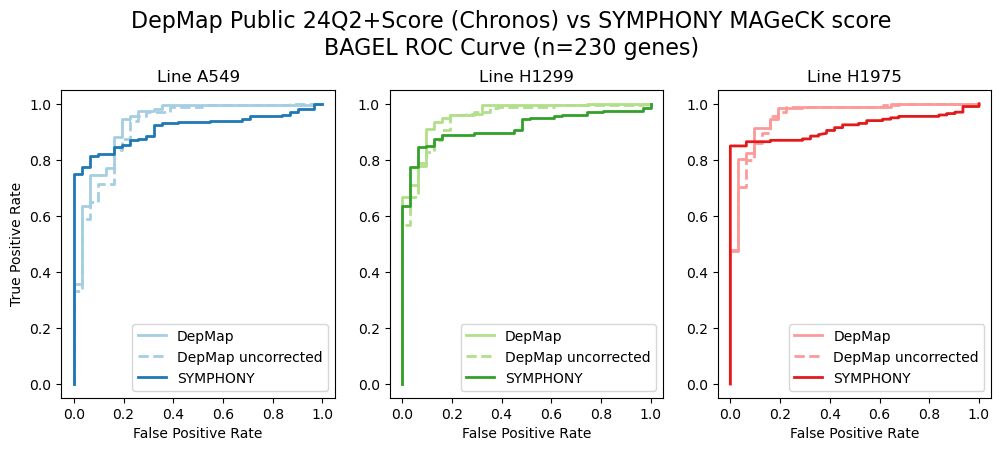

In [8]:
# Plot ROC curves for SYMPHONY vs DepMap; across all our cell lines
fig, axs = pl.subplots(1, 3, figsize=(4*3,4))
cmap = get_cmap('Paired')

i = 0
for ax, line in zip(axs, ['A549', 'H1299', 'H1975']):
    # DepMap
    sdf = super_df.loc[[line], 'DepMap Chronos'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    fpr, tpr, thresholds = roc_curve(sdf[mask].essentiality=='essential', -sdf[mask].score)
    style ='-'
    color = cmap(i)
    ax.plot(fpr, tpr, label="DepMap", linewidth=2, linestyle=style, color=color)
    
    # DepMap uncorrected
    sdf = super_df.loc[[line], 'DepMap uncorrected'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    fpr, tpr, thresholds = roc_curve(sdf[mask].essentiality=='essential', -sdf[mask].score)
    style ='--'
    color = cmap(i)
    ax.plot(fpr, tpr, label="DepMap uncorrected", linewidth=2, linestyle=style, color=color)
    i += 1
    
    # SYMPHONY
    sdf = super_df.loc[[line], 'SYMPHONY'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    fpr, tpr, thresholds = roc_curve(sdf[mask].essentiality=='essential', -sdf[mask].score)
    style ='-'
    color = cmap(i)
    ax.plot(fpr, tpr, label="SYMPHONY", linewidth=2, linestyle=style, color=color)
    i += 1
    
    ax.legend()
    ax.set_xlabel('False Positive Rate')
    if ax == axs[0]: ax.set_ylabel('True Positive Rate')
    ax.set_title(f'Line {line}')
pl.suptitle(f'DepMap Public 24Q2+Score (Chronos) vs SYMPHONY MAGeCK score\nBAGEL ROC Curve (n={(mask).sum()} genes)', y=1.08, fontsize=16)
pl.savefig(f'../results/figures/depmap_vs_symphony_ROCAUC.pdf', bbox_inches='tight', dpi=300)
pl.show()


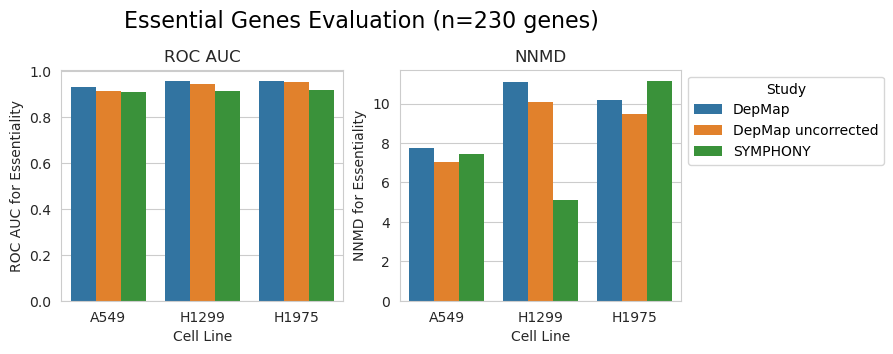

In [9]:
# AUC scores
from sklearn.metrics import roc_auc_score
aucs = {}
nnmds = {}
for line in ['A549', 'H1299', 'H1975']:
    # DepMap
    sdf = super_df.loc[[line], 'DepMap Chronos'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    aucs[(line, 'DepMap')] = roc_auc_score(sdf[mask].essentiality=='essential', -sdf[mask].score)
    nnmds[(line, 'DepMap')] = get_nnmd(sdf, score_column='score')
    
    # DepMap
    sdf = super_df.loc[[line], 'DepMap uncorrected'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    aucs[(line, 'DepMap uncorrected')] = roc_auc_score(sdf[mask].essentiality=='essential', -sdf[mask].score)
    nnmds[(line, 'DepMap uncorrected')] = get_nnmd(sdf, score_column='score')
    
    # SYMPHONY
    sdf = super_df.loc[[line], 'SYMPHONY'].T
    sdf.columns = ['score']
    sdf['essentiality'] = annotate_essentiality(sdf.index)
    mask = (sdf.essentiality!='unknown') & (sdf.index.isin(gene_overlap))
    aucs[(line, 'SYMPHONY')] = roc_auc_score(sdf[mask].essentiality=='essential', -sdf[mask].score)
    nnmds[(line, 'SYMPHONY')] = get_nnmd(sdf, score_column='score')
auc_df = pd.DataFrame(aucs, index=['AUC']).T.reset_index().rename(columns={'level_0':'line', 'level_1':'origin'})
nnmd_df = pd.DataFrame(nnmds, index=['NNMD']).T.reset_index().rename(columns={'level_0':'line', 'level_1':'origin'})

with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 2, figsize=(4*2,3), gridspec_kw=dict(hspace=0.7))
ax = axs[0]
sns.barplot(data=auc_df, x='line', y='AUC', hue='origin', ax=ax)
ax.legend_.remove()
ax.set_xlabel('Cell Line')
ax.set_ylabel('ROC AUC for Essentiality')
ax.set_title('ROC AUC')

ax = axs[1]
sns.barplot(data=nnmd_df, x='line', y='NNMD', hue='origin', ax=ax)
ax.set_xlabel('Cell Line')
ax.set_ylabel('NNMD for Essentiality')
ax.set_title('NNMD')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title='Study')

pl.suptitle(f'Essential Genes Evaluation (n={mask.sum()} genes)', fontsize=16, y=1.08)

pl.savefig(f'../results/figures/depmap_vs_symphony_ROCAUC_NNDM_barplots.pdf', bbox_inches='tight', dpi=300)
pl.show()

# Which known non/ess genes are most different? Can we explain why they are different?

In [17]:
super_df_ = pd.concat({'SYMPHONY': tab, 'DepMap Chronos': df_, 'DepMap uncorrected': unc_df}, axis=0, join='inner').T
super_df_['essentiality'] = annotate_essentiality(super_df_.index)
ddr_genes = pd.read_csv('../resources/HALLMARK_DNA_REPAIR.v2023.2.Hs.tsv', sep='\t', index_col=0).loc['GENE_SYMBOLS'][0].split(',')
super_df_['ddr'] = super_df_.index.isin(ddr_genes)
super_df_['ddr'] = super_df_['ddr'].replace({True: 'DDR', False: 'Non-DDR'})

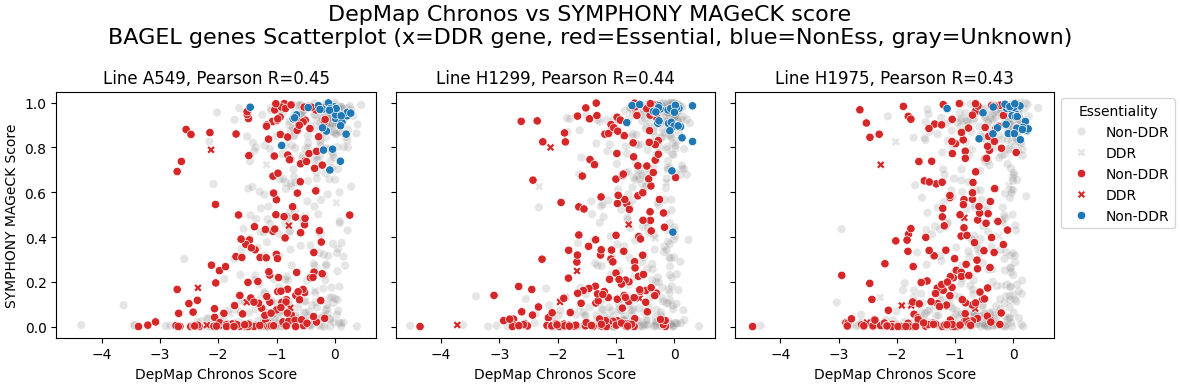

In [30]:
fig, axs = pl.subplots(1, 3, figsize=(4*3,4), sharex=True, sharey=True)
for line, ax in zip(['A549', 'H1299', 'H1975'], axs):
    y = ('SYMPHONY', line)
    x = ('DepMap Chronos', line)
    sns.scatterplot(data=super_df_[super_df_.essentiality == 'unknown'], 
                    x=x, y=y, ax=ax, style='ddr', color='gray',
                    alpha=0.2)
    sns.scatterplot(data=super_df_[super_df_.essentiality == 'essential'], 
                    x=x, y=y, ax=ax, style='ddr', color='tab:red',
                    )
    sns.scatterplot(data=super_df_[super_df_.essentiality == 'non-essential'], 
                    x=x, y=y, ax=ax, style='ddr', color='tab:blue',
                    )
    # peason correlation
    from scipy.stats import pearsonr
    r, p = pearsonr(super_df_[x], super_df_[y])
    ax.set_title(f'Line {line}, Pearson R={r:.2f}')
    ax.set_ylabel('SYMPHONY MAGeCK Score')
    ax.set_xlabel('DepMap Chronos Score')
    
    # Legend placement
    if ax == axs[-1]:
        sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title='Essentiality')
    else:
        ax.legend_.remove()
pl.suptitle('DepMap Chronos vs SYMPHONY MAGeCK score\nBAGEL genes Scatterplot (x=DDR gene, red=Essential, blue=NonEss, gray=Unknown)', fontsize=16)
pl.tight_layout()
pl.savefig(f'../results/figures/depmap_vs_symphony_scatterplot.pdf', bbox_inches='tight', dpi=300)
pl.show()

## Are there outliers? What is their function?

In [31]:
cell_line = 'A549'

In [37]:
super_df_[(super_df_.loc[:, 
                         ('SYMPHONY', cell_line)] > 0.6) &  # non-essential in SYMPHONY
                         (super_df_.loc[:, ('DepMap Chronos', cell_line)] < -2)  # essential in DepMap
                         ]

SYMPHONY                   DepMap Chronos                      \
            A549    H1299    H1975           A549     H1299     H1975   
DDX49    0.73762  0.82501  0.90466      -2.631509 -1.866063 -1.350221   
DTL      0.86670  0.82525  0.84545      -2.142241 -2.253027 -2.461829   
LCE2C    0.63683  0.69842  0.84355      -2.081350 -0.575861 -1.713474   
PAM16    0.82595  0.87721  0.91336      -2.151765 -1.620227 -1.508860   
POLR2C   0.78972  0.80037  0.72271      -2.123024 -2.120211 -2.276962   
POLR3A   0.88049  0.91684  0.90948      -2.550601 -2.623203 -2.523698   
PRELID1  0.85825  0.91882  0.96832      -2.466649 -2.348978 -2.634609   
RPL36    0.69261  0.65404  0.73730      -2.704213 -2.421486 -1.622410   
YARS1    0.95677  0.53264  0.93926      -2.019161 -2.318148 -2.154894   

        DepMap uncorrected                     essentiality      ddr  
                      A549     H1299     H1975                        
DDX49            -2.904432 -1.910446 -1.252429    essential  Non-DDR  
DTL              -2.203403 -2.687857 -2.732025    essential  Non-DDR  
LCE2C            -2.240825 -0.542294 -1.619924      unknown  Non-DDR  
PAM16            -2.285536 -1.857337 -1.381493      unknown  Non-DDR  
POLR2C           -2.234058 -2.073457 -2.229541    essential      DDR  
POLR3A           -2.612890 -3.175370 -2.807077    essential  Non-DDR  
PRELID1          -2.641239 -2.458767 -2.726311    essential  Non-DDR  
RPL36            -2.961845 -2.377730 -1.399516    essential  Non-DDR  
YARS1            -2.025604 -2.625452 -2.666713      unknown  Non-DDR

In [41]:
super_df_[(super_df_.loc[:, 
                         ('SYMPHONY', cell_line)] < 0.2) &  # essential in SYMPHONY
                         (super_df_.loc[:, ('DepMap Chronos', cell_line)] > 0)  # non-essential in DepMap
                         ]

SYMPHONY                     DepMap Chronos                      \
             A549     H1299     H1975           A549     H1299     H1975   
ANXA2    0.070477  0.015310  0.179460       0.058389  0.040714 -0.047389   
ATP5MC3  0.178570  0.166780  0.187070       0.080556 -0.093466  0.060375   
CLDN12   0.119030  0.073133  0.157660       0.050094  0.158111  0.091709   
EML4     0.123700  0.151500  0.136000       0.008357 -0.075741 -0.124097   
FUS      0.053471  0.024322  0.085199       0.037025 -0.099872 -0.062656   
KRT18    0.016882  0.015141  0.016567       0.072553  0.117978 -0.039994   
LDHB     0.014282  0.005058  0.118160       0.103981 -0.026726 -0.058306   
VIM      0.000100  0.000087  0.000132       0.109744 -0.025923 -0.025618   
ZNF146   0.000560  0.000838  0.000224       0.380113  0.427569  0.166983   
ZNF480   0.017994  0.028975  0.037356       0.145434  0.174254  0.094398   

        DepMap uncorrected                     essentiality      ddr  
                      A549     H1299     H1975                        
ANXA2             0.178137  0.261121  0.130669      unknown  Non-DDR  
ATP5MC3           0.263147  0.045945  0.282313      unknown  Non-DDR  
CLDN12            0.211238  0.300173  0.312310      unknown  Non-DDR  
EML4              0.068532  0.174576  0.135157      unknown  Non-DDR  
FUS               0.139443  0.039115  0.159496      unknown  Non-DDR  
KRT18             0.282663  0.188245 -0.239996      unknown  Non-DDR  
LDHB              0.254492  0.221131  0.144269      unknown  Non-DDR  
VIM               0.288926  0.183786  0.163103      unknown  Non-DDR  
ZNF146            0.388836  0.346267  0.387583      unknown  Non-DDR  
ZNF480            0.157058  0.178212  0.227251      unknown  Non-DDR